In [1]:
#Import required libraries
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#load the dataset

df = pd.read_csv('/content/final_dataset_std.csv', sep=';')

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:", df.isnull().sum().sum())


Dataset shape: (2632, 43)

Column names:
['P_ac-0', 'P_ac-1', 'P_ac-2', 'P_ac-3', 'P_ac-4', 'P_ac-5', 'P_ac-6', 'P_ac-7', 'P_cu-0', 'P_cu-1', 'P_cu-2', 'P_cu-3', 'P_cu-4', 'P_cu-5', 'P_cu-6', 'P_cu-7', 'T_out-0', 'T_out-1', 'T_out-2', 'T_out-3', 'T_out-4', 'T_out-5', 'T_out-6', 'T_out-7', 'T_MEAS-0', 'T_MEAS-1', 'T_MEAS-2', 'T_MEAS-3', 'T_MEAS-4', 'T_MEAS-5', 'T_MEAS-6', 'T_MEAS-7', 'T_celCC-0', 'T_celCC-1', 'T_celCC-2', 'T_celCC-3', 'T_celCC-4', 'T_celCC-5', 'T_celCC-6', 'T_celCC-7', 'TLHC', 'DoW', 'WeH']

First 5 rows:


,P_ac-0,P_ac-1,P_ac-2,P_ac-3,P_ac-4,P_ac-5,P_ac-6,P_ac-7,P_cu-0,P_cu-1,...,T_celCC-1,T_celCC-2,T_celCC-3,T_celCC-4,T_celCC-5,T_celCC-6,T_celCC-7,TLHC,DoW,WeH
0,1.483644,1.330373,1.177123,1.177087,2.861902,0.410917,0.104564,0.717323,-1.055378,-0.905744,...,1.135913,0.998844,0.724750,1.272878,1.341339,0.724663,0.313564,-0.307313,1.0,1.0
1,1.330427,1.483587,1.330334,1.177087,1.176840,2.861931,0.410944,0.104564,-0.905809,-1.055317,...,1.204436,1.135888,0.998839,0.724711,1.272820,1.341334,0.724681,-0.307313,1.0,1.0
2,1.330427,1.330373,1.483546,1.330296,1.176840,1.176859,2.861981,0.410944,-1.055378,-0.905744,...,1.341483,1.204411,1.135884,0.998794,0.724667,1.272815,1.341355,-0.352852,1.0,1.0
3,1.330427,1.330373,1.330334,1.483505,1.330028,1.176859,1.176893,2.861981,-0.905809,-1.055317,...,0.587727,1.341456,1.204406,1.135836,0.998744,0.724663,1.272836,-0.398391,1.0,1.0
4,1.330427,1.330373,1.330334,1.330296,1.483215,1.330047,1.176893,1.176893,-0.905809,-0.905744,...,0.930343,0.587709,1.341451,1.204357,1.135782,0.998739,0.724681,-0.352852,1.0,1.0



Missing values: 24


In [3]:
#Removing all the unneccessary columns and creating new datset

# Select useful input features
features = [
    'P_cu-0',       # Computing power
    'T_out-0',      # Outside temperature
    'T_MEAS-0',     # AC measured temperature
    'T_celCC-0',    # Cold-corridor temperature
    'TLHC',         # Hot-corridor temperature
    'DoW',          # Day of week
    'WeH'           # Weekday/holiday indicator
]

target = 'P_ac-0'    # Air-conditioning power

# Create a smaller dataset
model_df = df[features + [target]].copy()

print("Original dataset shape:", df.shape)
print("Selected dataset shape:", model_df.shape)

display(model_df.head())


Original dataset shape: (2632, 43)
Selected dataset shape: (2632, 8)


,P_cu-0,T_out-0,T_MEAS-0,T_celCC-0,TLHC,DoW,WeH,P_ac-0
0,-1.055378,1.818548,2.152423,1.204473,-0.307313,1.0,1.0,1.483644
1,-0.905809,1.788247,2.152423,1.341522,-0.307313,1.0,1.0,1.330427
2,-1.055378,1.773096,1.374093,0.587755,-0.352852,1.0,1.0,1.330427
3,-0.905809,1.788247,1.865670,0.930376,-0.398391,1.0,1.0,1.330427
4,-0.905809,1.803397,1.988564,1.135949,-0.352852,1.0,1.0,1.330427


In [4]:
#Cleaning the dataset

# Create a copy so the selected dataset remains unchanged
clean_df = model_df.copy()

# 1. Check the dataset before cleaning
print("Before cleaning:", clean_df.shape)
print("Missing values:\n", clean_df.isnull().sum())
print("Duplicate rows:", clean_df.duplicated().sum())

# 2. Convert selected columns to numeric if necessary
for col in clean_df.columns:
    clean_df[col] = pd.to_numeric(clean_df[col], errors='coerce')

# 3. Replace infinite values with missing values
clean_df = clean_df.replace([float('inf'), float('-inf')], float('nan'))

# 4. Remove rows with missing values
clean_df = clean_df.dropna()

# 5. Remove duplicate rows
clean_df = clean_df.drop_duplicates()

# 6. Reset row numbering
clean_df = clean_df.reset_index(drop=True)

# 7. Check the cleaned dataset
print("\nAfter cleaning:", clean_df.shape)
print("Remaining missing values:", clean_df.isnull().sum().sum())
print("Remaining duplicate rows:", clean_df.duplicated().sum())

display(clean_df.head())


Before cleaning: (2632, 8)
Missing values:
 P_cu-0       0
T_out-0      0
T_MEAS-0     1
T_celCC-0    1
TLHC         1
DoW          1
WeH          1
P_ac-0       0
dtype: int64
Duplicate rows: 1

After cleaning: (2630, 8)
Remaining missing values: 0
Remaining duplicate rows: 0


,P_cu-0,T_out-0,T_MEAS-0,T_celCC-0,TLHC,DoW,WeH,P_ac-0
0,-1.055378,1.818548,2.152423,1.204473,-0.307313,1.0,1.0,1.483644
1,-0.905809,1.788247,2.152423,1.341522,-0.307313,1.0,1.0,1.330427
2,-1.055378,1.773096,1.374093,0.587755,-0.352852,1.0,1.0,1.330427
3,-0.905809,1.788247,1.865670,0.930376,-0.398391,1.0,1.0,1.330427
4,-0.905809,1.803397,1.988564,1.135949,-0.352852,1.0,1.0,1.330427


,P_cu-0,T_out-0,T_MEAS-0,T_celCC-0,TLHC,DoW,WeH,P_ac-0
count,2630.000000,2630.000000,2630.000000,2630.000000,2630.000000,2630.000000,2630.000000,2630.000000
mean,-1.082676,0.588334,1.118087,0.348936,-0.427947,3.043346,0.707985,0.720644
std,0.161691,0.628980,0.598369,0.864972,0.412074,2.000291,0.454776,0.946574
min,-1.354518,-0.817650,-0.100636,-1.742072,-1.172550,0.000000,0.000000,-2.040362
25%,-1.204948,0.167137,0.595764,-0.166013,-0.853778,1.000000,0.000000,0.411121
50%,-1.055378,0.439847,1.128305,0.382182,-0.398391,3.000000,1.000000,0.870774
75%,-1.055378,1.015568,1.496987,0.861852,-0.170697,5.000000,1.000000,1.177209
max,-0.457100,1.894301,2.807858,4.151018,0.649001,6.000000,1.000000,3.169039


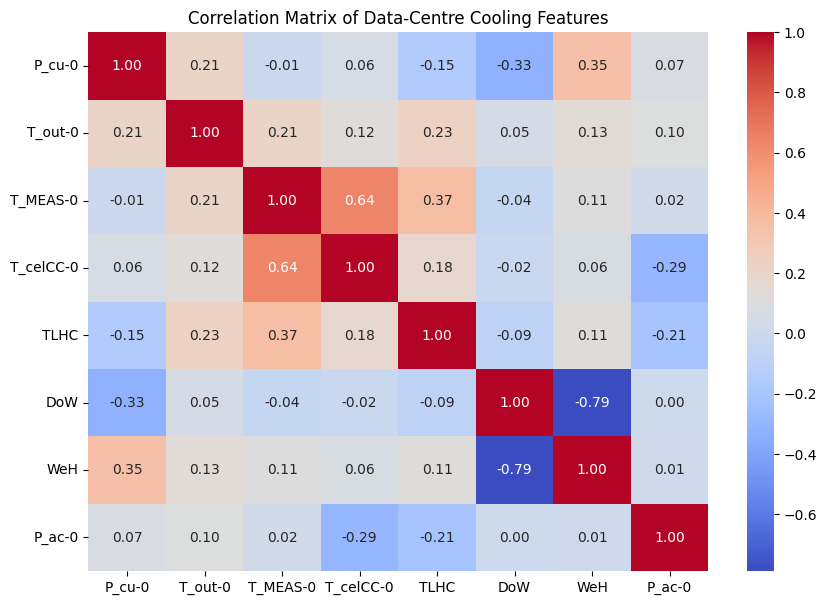

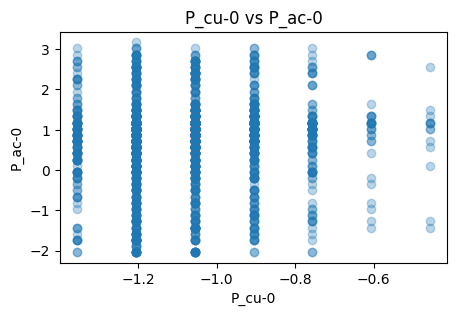

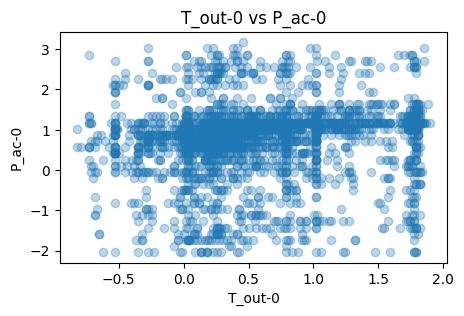

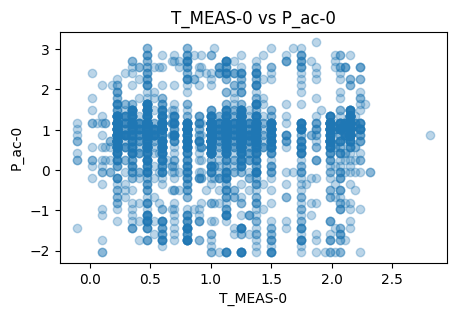

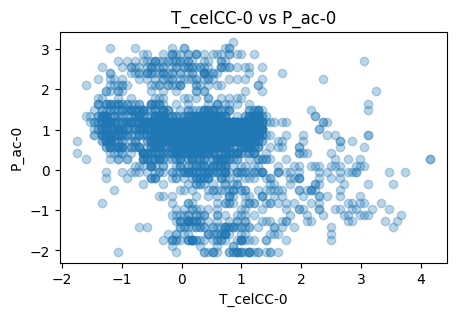

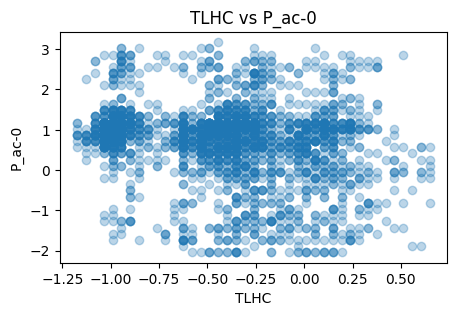

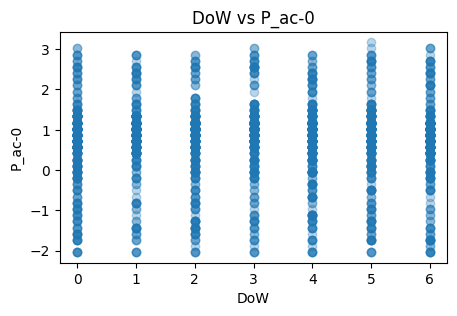

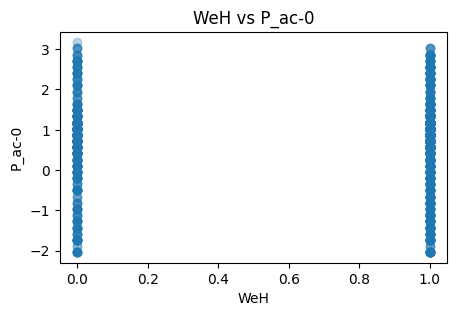

In [5]:
#EDA

# Statistical summary of the cleaned dataset
display(clean_df.describe())


# Calculate correlation
correlation = clean_df.corr()

# Visualize the correlation matrix
plt.figure(figsize=(10, 7))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Data-Centre Cooling Features')
plt.show()

target = 'P_ac-0'

for col in features:
    plt.figure(figsize=(5, 3))
    plt.scatter(clean_df[col], clean_df[target], alpha=0.3)
    plt.xlabel(col)
    plt.ylabel(target)
    plt.title(f'{col} vs {target}')
    plt.show()



In [6]:
#Split the data into training and testing


# Input features
X = clean_df[features]

# Target variable
y = clean_df['P_ac-0']

# Split the dataset: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training input:", X_train.shape)
print("Testing input:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training input: (2104, 7)
Testing input: (526, 7)
Training target: (2104,)
Testing target: (526,)


In [7]:
#Train 2 models

# Model 1: Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Model 2: Random Forest Regression
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

print("Both models trained successfully!")


Both models trained successfully!


In [8]:
#Evaluate model performance
models = {
    "Linear Regression": lr_model,
    "Random Forest": rf_model
}

results = []

for name, model in models.items():
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))


,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.5473,0.8173,0.2335
1,Random Forest,0.4795,0.6943,0.4469


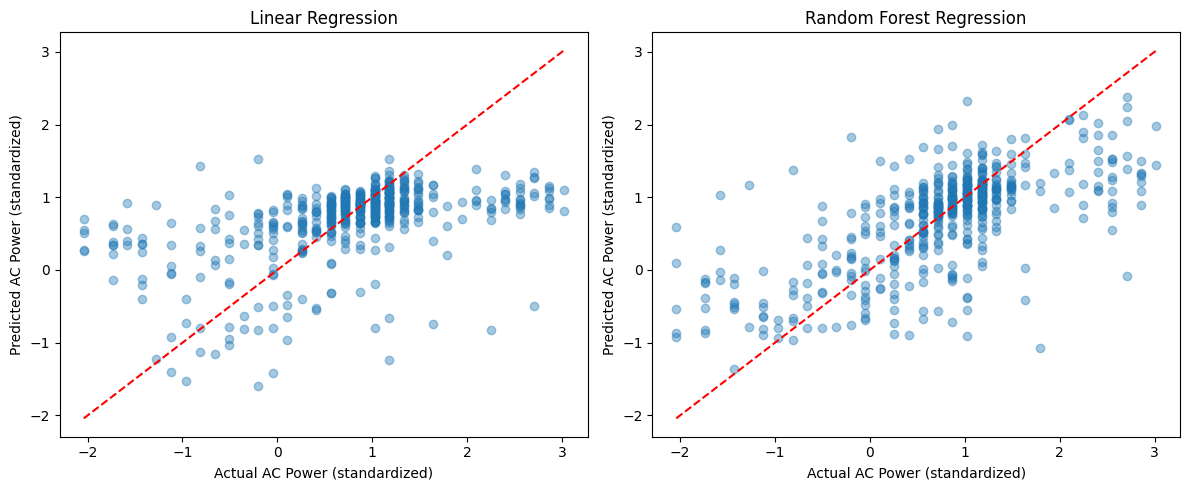

In [9]:
#Visualize actual vs predicted values

# Predict using the test data
lr_predictions = lr_model.predict(X_test)
rf_predictions = rf_model.predict(X_test)

# Plot predictions from both models
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(y_test, lr_predictions, alpha=0.4)
axes[0].set_title("Linear Regression")
axes[0].set_xlabel("Actual AC Power (standardized)")
axes[0].set_ylabel("Predicted AC Power (standardized)")

axes[1].scatter(y_test, rf_predictions, alpha=0.4)
axes[1].set_title("Random Forest Regression")
axes[1].set_xlabel("Actual AC Power (standardized)")
axes[1].set_ylabel("Predicted AC Power (standardized)")

for ax in axes:
    ax.plot(
        [y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        'r--'
    )

plt.tight_layout()
plt.show()


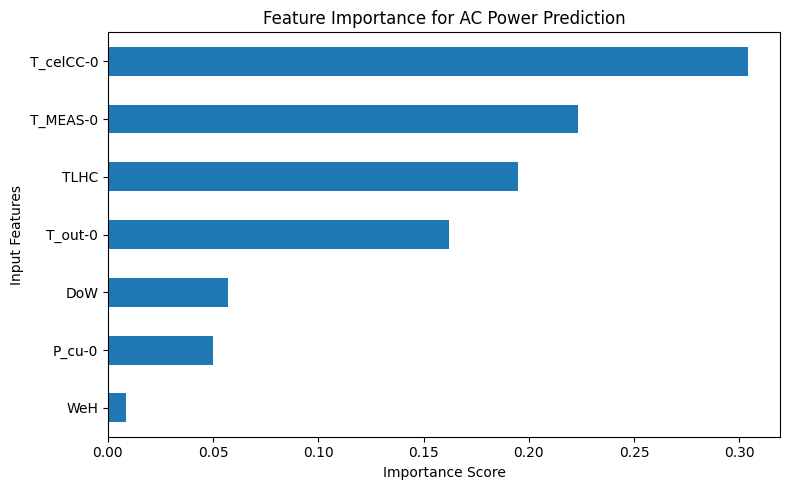

T_celCC-0    0.304173
T_MEAS-0     0.223357
TLHC         0.194977
T_out-0      0.161989
DoW          0.056859
P_cu-0       0.050108
WeH          0.008538
dtype: float64


In [10]:

# Get feature importance from Random Forest
importance = pd.Series(
    rf_model.feature_importances_,
    index=features
).sort_values(ascending=True)

# Plot feature importance
plt.figure(figsize=(8, 5))
importance.plot(kind='barh')
plt.xlabel('Importance Score')
plt.ylabel('Input Features')
plt.title('Feature Importance for AC Power Prediction')
plt.tight_layout()
plt.show()

print(importance.sort_values(ascending=False))


In [11]:

# Create a copy of the test data
scenarios = X_test.iloc[:100].copy()

# Keep all features unchanged except cold-corridor temperature
baseline = scenarios.copy()
cooler = scenarios.copy()

# Test a 0.5-standard-deviation decrease
# Values are standardized, not degrees Celsius
cooler['T_celCC-0'] = cooler['T_celCC-0'] - 0.5

# Predict AC power for both scenarios
baseline_predictions = rf_model.predict(baseline)
cooler_predictions = rf_model.predict(cooler)

# Compare average predictions
baseline_avg = baseline_predictions.mean()
cooler_avg = cooler_predictions.mean()

print("Baseline predicted AC power:", round(baseline_avg, 4))
print("Modified scenario prediction:", round(cooler_avg, 4))
print("Difference:", round(cooler_avg - baseline_avg, 4))


Baseline predicted AC power: 0.6791
Modified scenario prediction: 1.0612
Difference: 0.3821


In [12]:

# Compare different temperature scenarios
temperature_features = [
    'T_celCC-0',
    'T_MEAS-0',
    'TLHC',
    'T_out-0'
]

scenario_results = []

for feature in temperature_features:
    modified = scenarios.copy()

    # Decrease one feature by 0.5 standardized units
    modified[feature] = modified[feature] - 0.5

    predictions = rf_model.predict(modified)

    scenario_results.append({
        'Changed Feature': feature,
        'Average Predicted AC Power': predictions.mean(),
        'Difference from Baseline':
            predictions.mean() - rf_model.predict(scenarios).mean()
    })

display(pd.DataFrame(scenario_results).round(4))


,Changed Feature,Average Predicted AC Power,Difference from Baseline
0,T_celCC-0,1.0612,0.3821
1,T_MEAS-0,-0.0008,-0.6799
2,TLHC,0.9330,0.2539
3,T_out-0,0.6039,-0.0752


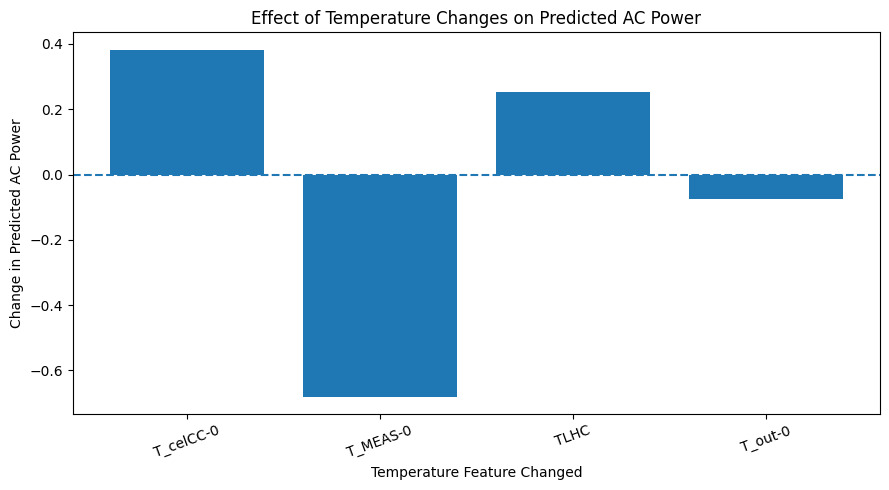

In [13]:
results_df = pd.DataFrame(scenario_results)

plt.figure(figsize=(9, 5))
plt.bar(
    results_df['Changed Feature'],
    results_df['Difference from Baseline']
)
plt.axhline(y=0, linestyle='--')
plt.xlabel('Temperature Feature Changed')
plt.ylabel('Change in Predicted AC Power')
plt.title('Effect of Temperature Changes on Predicted AC Power')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [14]:
# Save model evaluation results
results_df_models = pd.DataFrame(results)
results_df_models.to_csv('model_evaluation.csv', index=False)

# Save temperature scenario results
results_df.to_csv('temperature_scenarios.csv', index=False)

print("Results saved successfully!")

Results saved successfully!


In [15]:
from google.colab import files

files.download('model_evaluation.csv')
files.download('temperature_scenarios.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>